Cihaz: mps | Test resmi: 270


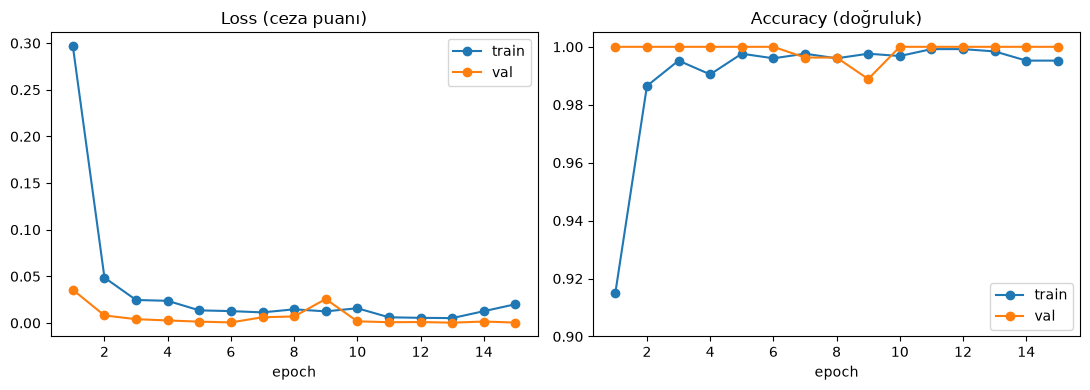

In [4]:
import sys 
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import ConfusionMatrixDisplay,classification_report,confusion_matrix
sys.path.append("../src")
from dataset import IMG_DIR,get_loaders
from train_classifier import build_model,get_device
from voc_to_yolo import CLASSES
device=get_device()
model=build_model(len(CLASSES))
model.load_state_dict(torch.load("../models/resnet18_best.pt",map_location=device))
model.to(device).eval()
_, _, test_loader = get_loaders()
print("Cihaz:", device, "| Test resmi:", len(test_loader.dataset))
hist=pd.read_csv("../reports/classifier_history.csv")
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="val")
axes[0].set_title("Loss (ceza puanı)")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(hist["epoch"], hist["train_acc"], marker="o", label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy (doğruluk)")
axes[1].set_xlabel("epoch")
axes[1].set_ylim(0.9, 1.005)
axes[1].legend()

plt.tight_layout()
fig.savefig("../reports/figures/06_learning_curves.png", dpi=150)
plt.show()



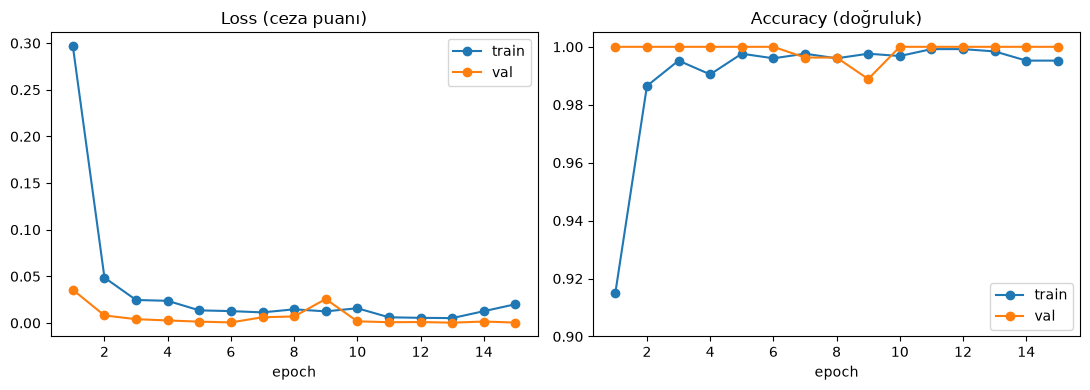

In [5]:
hist=pd.read_csv("../reports/classifier_history.csv")
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(hist["epoch"], hist["train_loss"], marker="o", label="train")
axes[0].plot(hist["epoch"], hist["val_loss"], marker="o", label="val")
axes[0].set_title("Loss (ceza puanı)")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(hist["epoch"], hist["train_acc"], marker="o", label="train")
axes[1].plot(hist["epoch"], hist["val_acc"], marker="o", label="val")
axes[1].set_title("Accuracy (doğruluk)")
axes[1].set_xlabel("epoch")
axes[1].set_ylim(0.9, 1.005)
axes[1].legend()

plt.tight_layout()
fig.savefig("../reports/figures/06_learning_curves.png", dpi=150)
plt.show()



In [7]:
y_true, y_pred, y_prob = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        probs = torch.softmax(outputs, dim=1).cpu()
        y_prob.append(probs)
        y_pred.extend(probs.argmax(dim=1).tolist())
        y_true.extend(labels.tolist())

y_prob = torch.cat(y_prob).numpy()
y_true, y_pred = np.array(y_true), np.array(y_pred)

print("Test accuracy:", round((y_true == y_pred).mean(), 4))
print("Yanlış sayısı:", (y_true != y_pred).sum(), "/", len(y_true))
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

Test accuracy: 0.9963
Yanlış sayısı: 1 / 270
                 precision    recall  f1-score   support

        crazing      1.000     1.000     1.000        45
      inclusion      0.978     1.000     0.989        45
        patches      1.000     1.000     1.000        45
 pitted_surface      1.000     1.000     1.000        45
rolled-in_scale      1.000     1.000     1.000        45
      scratches      1.000     0.978     0.989        45

       accuracy                          0.996       270
      macro avg      0.996     0.996     0.996       270
   weighted avg      0.996     0.996     0.996       270



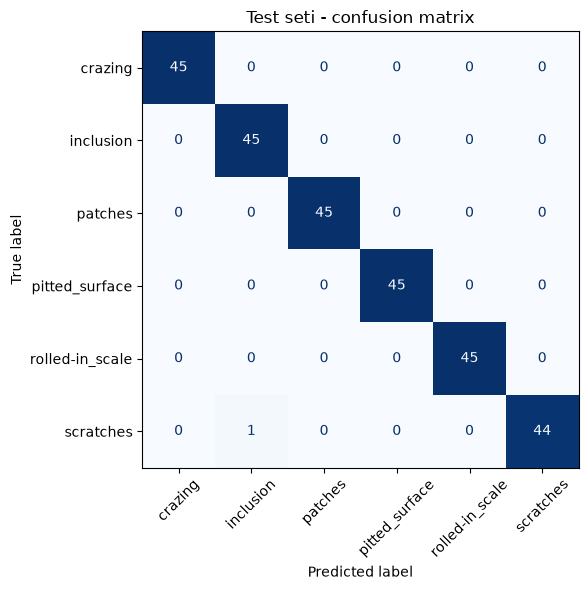

In [8]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("Test seti - confusion matrix")
plt.tight_layout()
fig.savefig("../reports/figures/07_confusion_matrix.png", dpi=150)
plt.show()

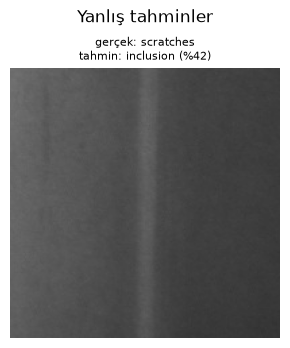

In [9]:
test_files = test_loader.dataset.df["file"].values
confidence = y_prob.max(axis=1)
wrong = np.where(y_true != y_pred)[0]

if len(wrong) > 0:
    show, title = wrong[:6], "Yanlış tahminler"
else:
    show, title = np.argsort(confidence)[:6], "En az emin olduğu 6 doğru tahmin"

fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3.6))
axes = np.atleast_1d(axes)
for ax, i in zip(axes, show):
    img = plt.imread(IMG_DIR / test_files[i])
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"gerçek: {CLASSES[y_true[i]]}\n"
                 f"tahmin: {CLASSES[y_pred[i]]} (%{confidence[i] * 100:.0f})", fontsize=8)
    ax.axis("off")

fig.suptitle(title)
plt.tight_layout()
fig.savefig("../reports/figures/08_hard_examples.png", dpi=150)
plt.show()

## Katman 3 sonuçları

**Test seti (270 resim, ilk ve tek değerlendirme)**
- Test accuracy: **%99,63** (1 yanlış / 270)
- 6 sınıftan 4'ü kusursuz (precision, recall, F1 = 1,000)
- Tek hata: Bir **scratches** resmi **inclusion** olarak tahmin edildi

**Öğrenme eğrisi**
- Ezberleme yok: val loss train ile birlikte düşük kaldı
- Val loss < train loss: Artırma sadece eğitimde, bu yüzden eğitim resimleri daha zor

**Yanlış tahmin**
- Çok soluk, belirsiz bir dikey şerit; insan için de zor
- Model sadece **%42 emindi** → ne zaman bilmediğini biliyor
- **Fikir:** Güven eşiği (örn. %60 altı → insana gönder)

**EDA tahminleri**
- Crazing ↔ rolled-in_scale, patches ↔ rolled-in_scale karışmadı ✗
- Pitted_surface parlaklıktan etkilenmedi ✗
- Beklenmeyen: scratches ↔ inclusion (ikisi de ince, dikey)
- Model, bizim gözümüzün göremediği doku farklarını yakalıyor

**Sınırlılıklar**
- Görev kolay; yüksek skor tek başına kanıt değil
- Model parlaklık gibi kestirme yollara bakıyor olabilir → **Katman 4 (Grad-CAM)**
- Başka fabrikada başarı düşebilir → **Katman 7**